# Data Mining Project

#### HIERARCHICAL CLUSTERING
* Choose the attributes, the distance function, analyse several dendrograms.

### Informazioni Generali
* **Corso:** Data Mining
* **Università:** Università di Pisa
* **Anno Accademico:** 2024/2025

### Autore
* **Studente:** Giuseppe Muschetta
* **Matricola:** 564026

### Dataset Utilizzato
* **Nome:** IMDb Dataset
* **Descrizione:** Dataset consisting of 21909 points in 23 dimensions

In [1]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Global style setting for Seaborn and matplotlib plots
plt.style.use("dark_background")
sns.set_theme(
    style="darkgrid",
    context="notebook",
    palette="icefire",  # rocket, mako, crest, vlag, flare
    font="sans-serif",
    font_scale=1.1
)

plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.edgecolor'] = 'white'
plt.rcParams['axes.labelcolor'] = 'white'
plt.rcParams['xtick.color'] = 'lightgray'
plt.rcParams['ytick.color'] = 'lightgray'
plt.rcParams['text.color'] = 'white'
plt.rcParams['grid.color'] = '#444444'   # darker grid
plt.rcParams['grid.linestyle'] = '--'    # tratteggiata fine
plt.rcParams['grid.alpha'] = 0.3         # trasparente, eterea
plt.rcParams['figure.facecolor'] = '#111111'
plt.rcParams['axes.facecolor'] = '#111111'
plt.rcParams['savefig.facecolor'] = '#111111'

# Other palette examples:
# dark mode: icefire, rocket, mako, crest, vlag, flare
# white theme: viridis, magma, plasma, inferno, cividis,

# Griglia ultra soft per grafici dark
# plt.rcParams['grid.color'] = '#222222'   # ancora più scura e discreta


In [3]:
# Create Directory for Plots ---
# To keep our project organized, we'll save all generated plots to a specific
# directory. This code creates a 'plots' directory if it doesn't already exist.

plots_dir = 'plots_clustering/hierarchical/'

if not os.path.exists(plots_dir):
    os.makedirs(plots_dir, exist_ok=True)
    print(f"Directory {plots_dir} created successfully.")
else:
    print(f"Directory {plots_dir} already exists.")

# Load the dataset ---
# Load the dataset from the provided CSV file into a pandas DataFrame, which is
# the primary data structure we will use for our analysis.

# Define the file path
dataset_dir = 'dataset/'
dataset_train = 'train_prepared.csv'
dataset_test = 'test_prepared.csv'

# Load the data
try:
    df_train = pd.read_csv(dataset_dir + dataset_train)
    print(f"dataset '{dataset_train}' loaded successfully.")
    print(f"The dataset contains {df_train.shape[0]} rows and {df_train.shape[1]} columns.")
    df_test = pd.read_csv(dataset_dir + dataset_test)
    print(f"dataset '{dataset_test}' loaded successfully.")
    print(f"The dataset contains {df_test.shape[0]} rows and {df_test.shape[1]} columns.")
except FileNotFoundError:
    print(f"Error: The dataset in the dir '{dataset_dir}' was not found. Please check the file path.")
    exit(1)


Directory plots_clustering/hierarchical/ created successfully.
dataset 'train_prepared.csv' loaded successfully.
The dataset contains 15609 rows and 55 columns.
dataset 'test_prepared.csv' loaded successfully.
The dataset contains 5478 rows and 55 columns.


In [4]:
df_train.head()

,originalTitle,startYear,endYear,runtimeMinutes,awardWins,numVotes,totalImages,totalVideos,totalCredits,criticReviewsTotal,...,awardWins_proc,numVotes_proc,totalImages_proc,totalVideos_proc,runtimeMinutes_proc,totalCredits_proc,criticReviewsTotal_proc,awardNominationsExcludeWins_proc,numRegions_proc,userReviewsTotal_proc
0,Neogenic Nightmare Chapter 3: Hydro-Man,1995,\N,58,0,779,1,0,21,1,...,-0.33267,1.465542,-0.510552,-0.277418,0.236295,-0.367632,0.264517,-0.316269,-0.661879,-0.648047
1,Looping,1982,\N,58,0,11,1,0,1,0,...,-0.33267,-0.906068,-0.510552,-0.277418,0.236295,-2.524145,-0.517037,-0.316269,-0.661879,-0.648047
2,Idealnaya para,1992,\N,58,0,38,1,0,24,0,...,-0.33267,-0.236435,-0.510552,-0.277418,0.236295,-0.252666,-0.517037,-0.316269,-0.661879,-0.015936
3,MasterChef Celebrity México,2021,\N,58,0,15,22,0,56,0,...,-0.33267,-0.742626,1.535001,-0.277418,0.236295,0.488544,-0.517037,-0.316269,-0.661879,-0.648047
4,Lightdance,1995,\N,34,0,14,1,0,0,0,...,-0.33267,-0.779293,-0.510552,-0.277418,-0.452128,-3.147517,-0.517037,-0.316269,-0.661879,-0.015936


In [5]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15609 entries, 0 to 15608
Data columns (total 55 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   originalTitle                     15609 non-null  object 
 1   startYear                         15609 non-null  int64  
 2   endYear                           15609 non-null  object 
 3   runtimeMinutes                    15609 non-null  int64  
 4   awardWins                         15609 non-null  int64  
 5   numVotes                          15609 non-null  int64  
 6   totalImages                       15609 non-null  int64  
 7   totalVideos                       15609 non-null  int64  
 8   totalCredits                      15609 non-null  int64  
 9   criticReviewsTotal                15609 non-null  int64  
 10  awardNominationsExcludeWins       15609 non-null  int64  
 11  numRegions                        15609 non-null  int64  
 12  user

In [6]:
#### Scelta delle variabili per il clustering esplorativo
columns_for_clustering = [col for col in df_train.columns if col.endswith("_proc")]

"""
le colonne sono: [
 'startYear_proc',
 'awardWins_proc',
 'numVotes_proc',
 'totalImages_proc',
 'totalVideos_proc',
 'runtimeMinutes_proc',
 'totalCredits_proc',
 'criticReviewsTotal_proc',
 'awardNominationsExcludeWins_proc',
 'numRegions_proc',
 'userReviewsTotal_proc']
"""

X = df_train[columns_for_clustering]

###HIERARCHICAL AGGLOMERATIVE CLUSTERING

#### Comparative Analysis of all Linkage methods: Single, Complete, Average and Ward linkage.

Nuovo limite di ricorsione impostato a: 15709
--- Inizio analisi per il linkage: 'single' ---


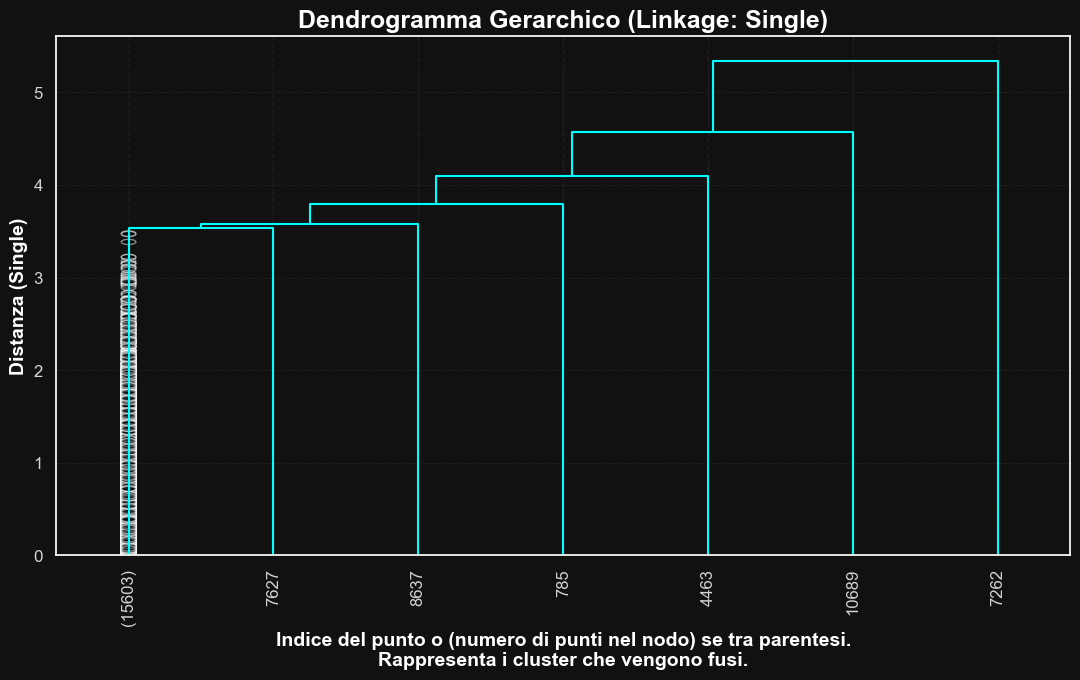

--- Analisi per 'single' completata in 4.11 secondi. Grafico salvato in 'plots_clustering/hierarchical/dendrogram_single.png' ---

--- Inizio analisi per il linkage: 'complete' ---


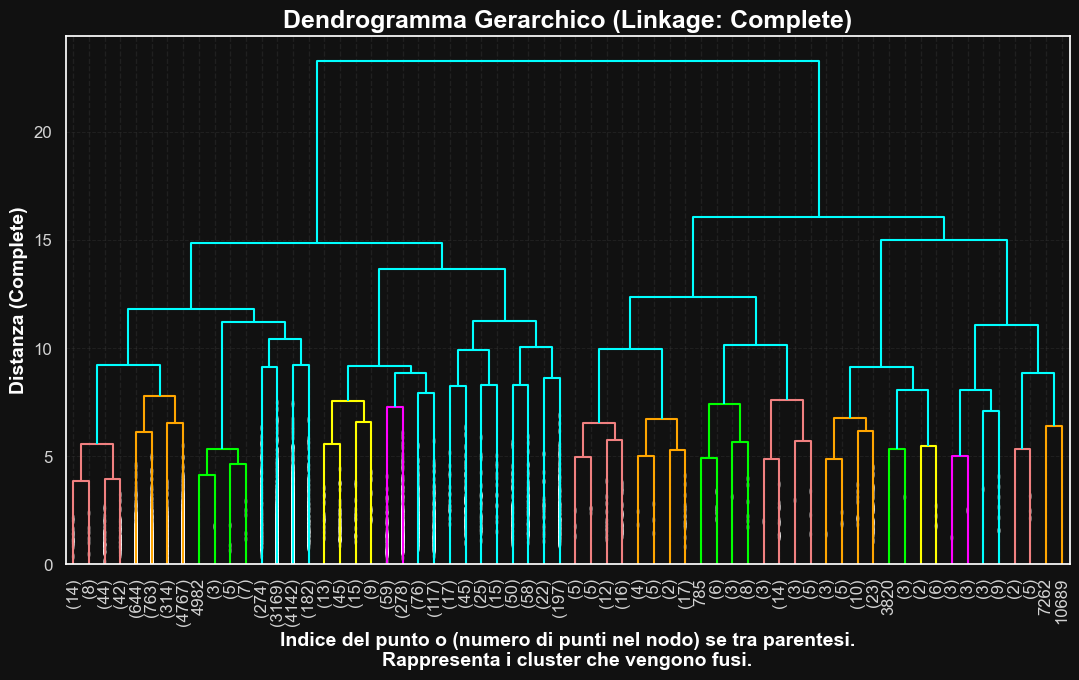

--- Analisi per 'complete' completata in 6.67 secondi. Grafico salvato in 'plots_clustering/hierarchical/dendrogram_complete.png' ---

--- Inizio analisi per il linkage: 'average' ---


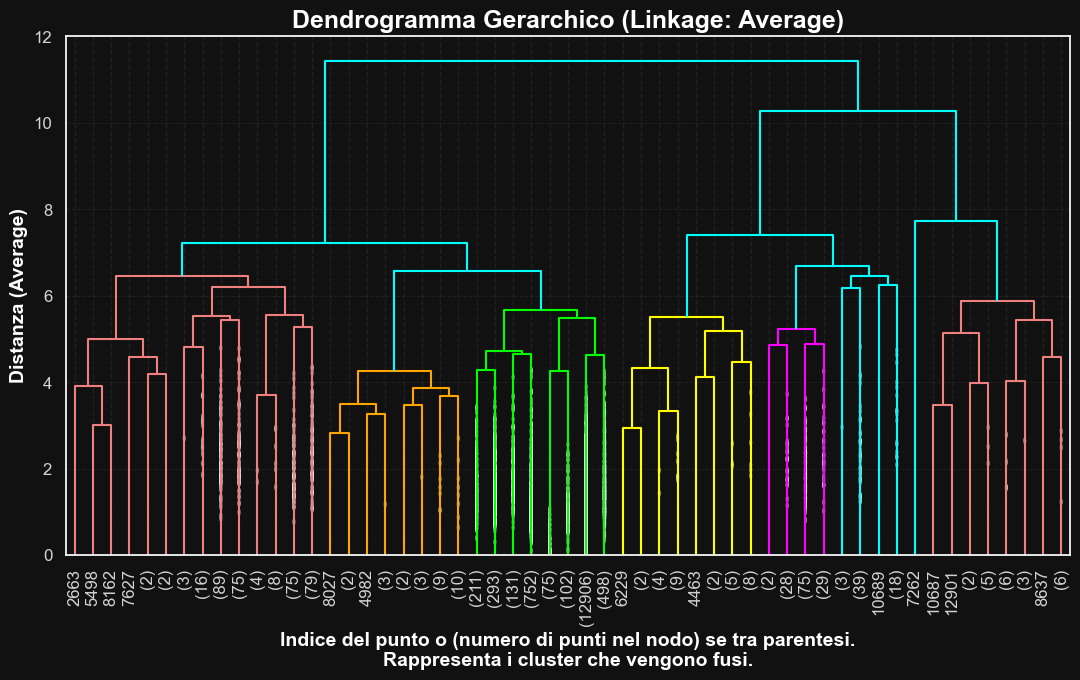

--- Analisi per 'average' completata in 6.81 secondi. Grafico salvato in 'plots_clustering/hierarchical/dendrogram_average.png' ---

--- Inizio analisi per il linkage: 'ward' ---


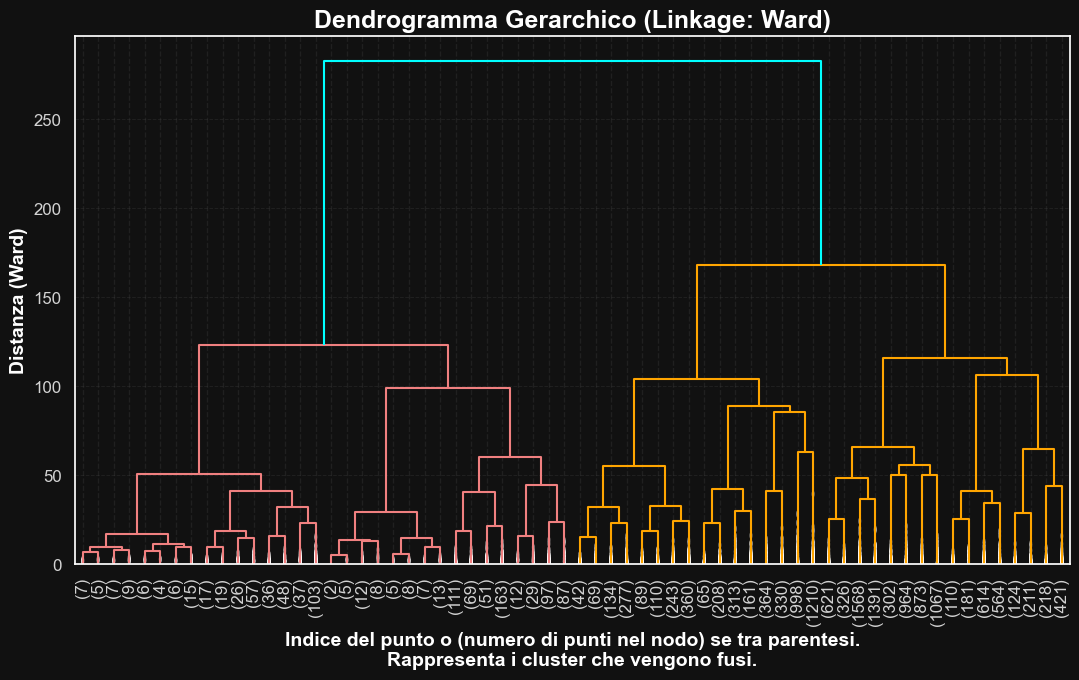

--- Analisi per 'ward' completata in 6.40 secondi. Grafico salvato in 'plots_clustering/hierarchical/dendrogram_ward.png' ---



In [15]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram
import time
import sys
from cycler import cycler

# Aumentiamo il limite di ricorsione di Python per gestire alberi molto profondi
# Lo impostiamo a un valore maggiore del numero di campioni per sicurezza
try:
    new_recursion_limit = len(X) + 100
    sys.setrecursionlimit(new_recursion_limit)
    print(f"Nuovo limite di ricorsione impostato a: {new_recursion_limit}")
except RecursionError: # In alcuni ambienti come Databricks questo potrebbe fallire
    print("Attenzione: Impossibile impostare un nuovo limite di ricorsione.")
    pass


# Definiamo una palette di colori brillanti, perfetta per lo sfondo scuro.
# 'cyan', 'magenta, 'yellow, 'lime', 'orange', 'lightcoral'
dark_palette = ['cyan', 'lightcoral', 'orange', 'lime', 'yellow', 'magenta']
plt.rcParams['axes.prop_cycle'] = cycler(color=dark_palette)
# dark_palette = ['#00FFFF', '#FF00FF', '#FFFF00', '#00FF00', '#FFA500', '#F08080']



# Lista dei metodi di linkage che vogliamo confrontare
linkage_methods = ['single', 'complete', 'average', 'ward']

# Iteriamo su ogni metodo di linkage
for method in linkage_methods:
    start_time = time.time()
    print(f"--- Inizio analisi per il linkage: '{method}' ---")

    # 1. Creiamo e addestriamo il modello SKLEARN per ottenere l'albero completo
    #    Impostiamo n_clusters=None e distance_threshold=0 per forzare il calcolo completo.
    #    compute_distances=True è fondamentale per ottenere le distanze di fusione.
    model = AgglomerativeClustering(
        n_clusters=None,
        distance_threshold=0,
        linkage=method,
        metric='euclidean',
        compute_distances=True
    )
    model.fit(X)

    # 2. Ricostruiamo la matrice di linkage Z in formato compatibile con SciPy
    #    Questo "ponte" ci permette di usare il motore di sklearn con il plotter di scipy.

    # Calcoliamo il numero di punti in ogni nodo non foglia (cluster)
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                # Se l'indice è minore del numero di campioni, è una foglia
                current_count += 1
            else:
                # Altrimenti, è un nodo già fuso, quindi prendiamo il suo conteggio
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    # Uniamo le informazioni per creare la matrice Z
    linkage_matrix = np.column_stack([model.children_, model.distances_, counts]).astype(float)

    # 3. Visualizziamo il Dendrogramma
    plt.figure(figsize=(11, 7))
    title = f'Dendrogramma Gerarchico (Linkage: {method.capitalize()})'
    plt.title(title, fontsize=18)


    # Usiamo color_threshold per applicare la nostra palette ai cluster principali.
    # Un valore di 175 è un buon punto di partenza per il linkage 'ward'.
    # Potrebbe essere necessario aggiustarlo per gli altri metodi.
    # Per 'ward' è una buona soglia, per gli altri potrebbe essere troppo alta/bassa.
    # Lo impostiamo in modo dinamico per un risultato migliore.
    threshold_map = {'ward': 175, 'complete': 8, 'average': 6.5, 'single': 3}
    color_thresh = threshold_map.get(method, np.median(linkage_matrix[:, 2]))


    # Usiamo truncate_mode per rendere leggibile il grafico con molti dati
    dendrogram(
        linkage_matrix,
        truncate_mode='level',
        p=5,  # Mostriamo gli ultimi 5 livelli di fusioni
        leaf_rotation=90.,
        leaf_font_size=12,
        show_contracted=True, # Mostra i nodi troncati con un triangolo
        color_threshold=color_thresh, # parametro importantissimo per i colori
    )

    plt.ylabel(f"Distanza ({method.capitalize()})", fontsize=14)
    plt.xlabel(
        "Indice del punto o (numero di punti nel nodo) se tra parentesi.\n"
        "Rappresenta i cluster che vengono fusi.",
        fontsize=14
    )
    plt.grid(axis='y', linestyle='--', linewidth=0.7)

    # Salviamo il grafico
    plot_filename = os.path.join(plots_dir, f'dendrogram_{method}.png')
    plt.savefig(plot_filename, dpi=300, bbox_inches='tight')
    plt.tight_layout()
    plt.show()

    end_time = time.time()
    print(f"--- Analisi per '{method}' completata in {end_time - start_time:.2f} secondi. Grafico salvato in '{plot_filename}' ---\n")

In [ ]:
#### AGGLOMERATIVE CLUSTRING USING WARD LINKAGE

--- Calcolo del modello finale con linkage: 'ward' ---


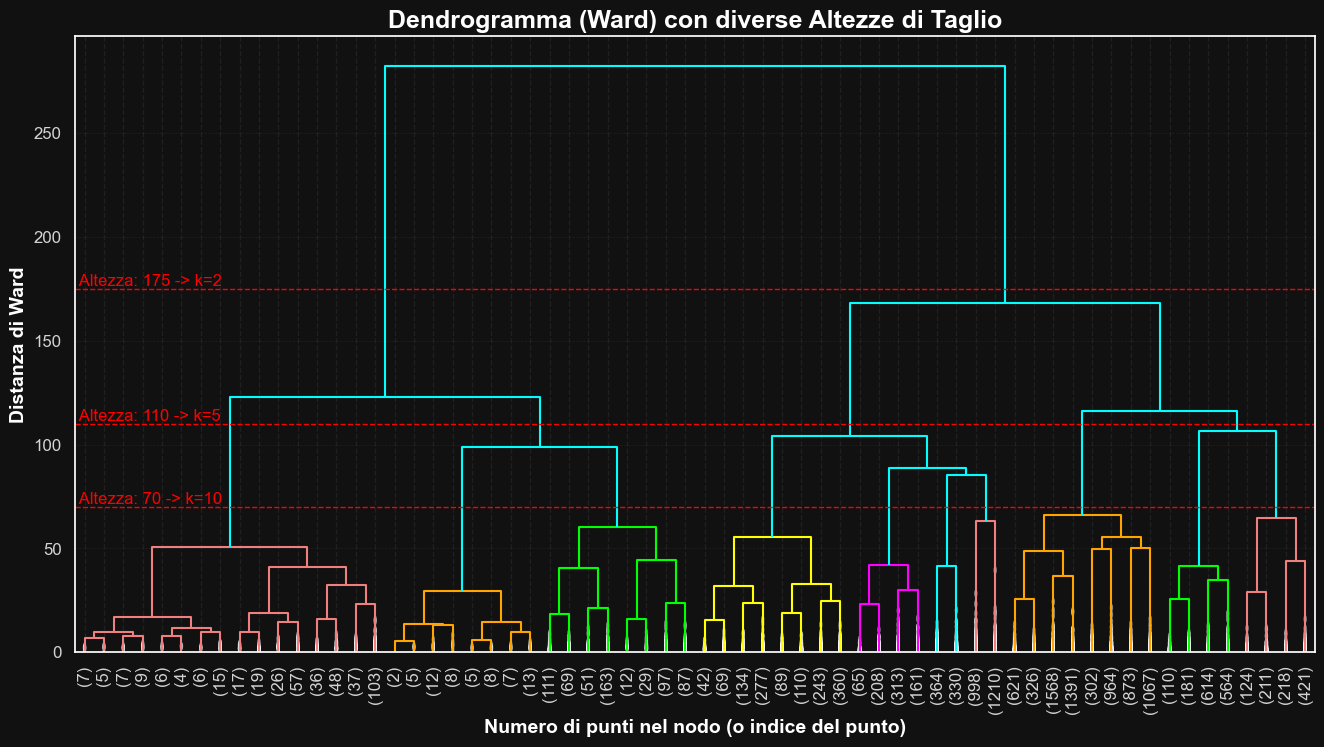


--- Esecuzione del clustering finale con k=5 ---

Assegnazione dei cluster completata. Ecco la distribuzione:
agg_cluster
0    2443
1     679
2    4973
3     402
4    7112
Name: count, dtype: int64


In [19]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, fcluster

# --- 1. RIGENERIAMO IL MODELLO E LA MATRICE DI LINKAGE SOLO PER 'WARD' ---
#    (Buona pratica per isolare il modello finale)
print("--- Calcolo del modello finale con linkage: 'ward' ---")

# Addestriamo il modello per ottenere la struttura completa dell'albero
model_ward = AgglomerativeClustering(
    n_clusters=None,
    distance_threshold=0,
    linkage='ward',
    metric='euclidean',
    compute_distances=True
).fit(X)

# Ricostruiamo la matrice di linkage Z come prima
counts = np.zeros(model_ward.children_.shape[0])
n_samples = len(model_ward.labels_)
for i, merge in enumerate(model_ward.children_):
    current_count = 0
    for child_idx in merge:
        if child_idx < n_samples:
            current_count += 1
        else:
            current_count += counts[child_idx - n_samples]
    counts[i] = current_count
linkage_matrix_ward = np.column_stack([model_ward.children_, model_ward.distances_, counts]).astype(float)

# --- 2. VISUALIZZAZIONE DEL DENDROGRAMMA CON DIVERSE IPOTESI DI TAGLIO ---
plt.figure(figsize=(16, 8))
plt.title('Dendrogramma (Ward) con diverse Altezze di Taglio', fontsize=18)

# Disegniamo il dendrogramma base
dendrogram(
    linkage_matrix_ward,
    truncate_mode='level',
    p=5,
    leaf_rotation=90.,
    leaf_font_size=12,
    show_contracted=True,
    color_threshold=70 # Impostiamo una soglia di colore base
)
plt.ylabel("Distanza di Ward", fontsize=14)
plt.xlabel("Numero di punti nel nodo (o indice del punto)", fontsize=14)

# DEFINIAMO LE ALTEZZE DI TAGLIO DA TESTARE
cut_heights = {
    'k=2': 175,
    'k=5': 110, # il nostro k ideale
    'k=10': 70
}

# Disegniamo una linea per ogni altezza di taglio
for k_label, height in cut_heights.items():
    plt.axhline(y=height, c='r', lw=1, linestyle='--')
    # Calcoliamo il numero esatto di cluster a quella altezza
    clusters = fcluster(linkage_matrix_ward, t=height, criterion='distance')
    k_found = len(np.unique(clusters))
    # Scriviamo il testo accanto alla linea
    plt.text(0, height, f' Altezza: {height} -> k={k_found}', va='bottom', ha='left', color='red', fontsize=12)

plt.grid(axis='y', linestyle='--', linewidth=0.5)
plot_filename = os.path.join(plots_dir, 'dendrogram_ward_final_cuts.png')
plt.savefig(plot_filename, dpi=300, bbox_inches='tight')
plt.show()


optimal_n_clusters = 5
# --- 3. ASSEGNAZIONE FINALE DEI CLUSTER CON K=7 ---
print(f"\n--- Esecuzione del clustering finale con k={optimal_n_clusters} ---")
final_agg_model = AgglomerativeClustering(
    n_clusters=optimal_n_clusters,
    linkage='ward',
    metric='euclidean'
)
# Usiamo fit_predict per ottenere direttamente le etichette
final_labels = final_agg_model.fit_predict(X)

# Aggiungiamo le etichette al DataFrame originale
df_train['agg_cluster'] = final_labels

print("\nAssegnazione dei cluster completata. Ecco la distribuzione:")
print(df_train['agg_cluster'].value_counts().sort_index())

--- Distribuzione dei Cluster (Gerarchico - Ward, k=7) ---
             Conteggio  Percentuale (%)
agg_cluster                            
0                 2443            15.65
1                  679             4.35
2                 4973            31.86
3                  402             2.58
4                 7112            45.56


/var/folders/4l/s_d8z1kx7h762hwfcv4xhtsh0000gn/T/ipykernel_90715/962321858.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


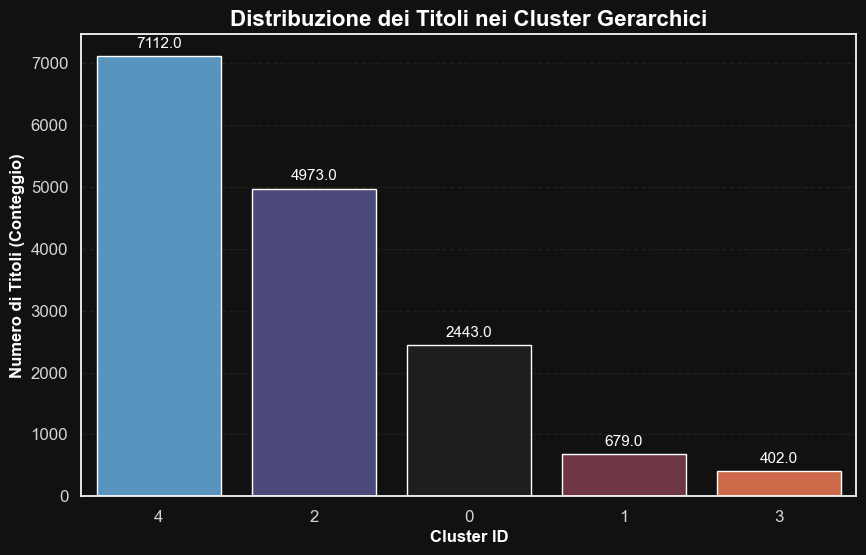

In [20]:
# --- 4. ANALISI DELLA DISTRIBUZIONE DEI CLUSTER ---

# Calcoliamo sia i conteggi assoluti che le percentuali
cluster_counts = df_train['agg_cluster'].value_counts()
cluster_percentages = df_train['agg_cluster'].value_counts(normalize=True) * 100

# Creiamo un DataFrame per una visualizzazione ordinata
distribution_df = pd.DataFrame({
    'Conteggio': cluster_counts,
    'Percentuale (%)': cluster_percentages
}).sort_index()

# Arrotondiamo le percentuali per una migliore leggibilità
distribution_df['Percentuale (%)'] = distribution_df['Percentuale (%)'].round(2)

print("--- Distribuzione dei Cluster (Gerarchico - Ward, k=7) ---")
print(distribution_df)


# --- 5. VISUALIZZAZIONE CON ISTOGRAMMA ---

plt.figure(figsize=(10, 6))
# Usiamo seaborn per un plot esteticamente gradevole e coerente
ax = sns.countplot(
    x='agg_cluster',
    data=df_train,
    order=cluster_counts.index, # Ordiniamo i cluster dal più grande al più piccolo
    palette="icefire"
)

plt.title('Distribuzione dei Titoli nei Cluster Gerarchici', fontsize=16)
plt.xlabel('Cluster ID', fontsize=12)
plt.ylabel('Numero di Titoli (Conteggio)', fontsize=12)

# Aggiungiamo le etichette con il conteggio sopra ogni barra
for p in ax.patches:
    ax.annotate(f'{p.get_height()}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 9),
                textcoords='offset points',
                color='white',
                fontsize=11)

# Salviamo il grafico
plot_filename = os.path.join(plots_dir, 'hierarchical_cluster_distribution.png')
plt.savefig(plot_filename, dpi=300, bbox_inches='tight')

plt.show()

In [ ]:
#### Visualizzazione Clusters in 2D

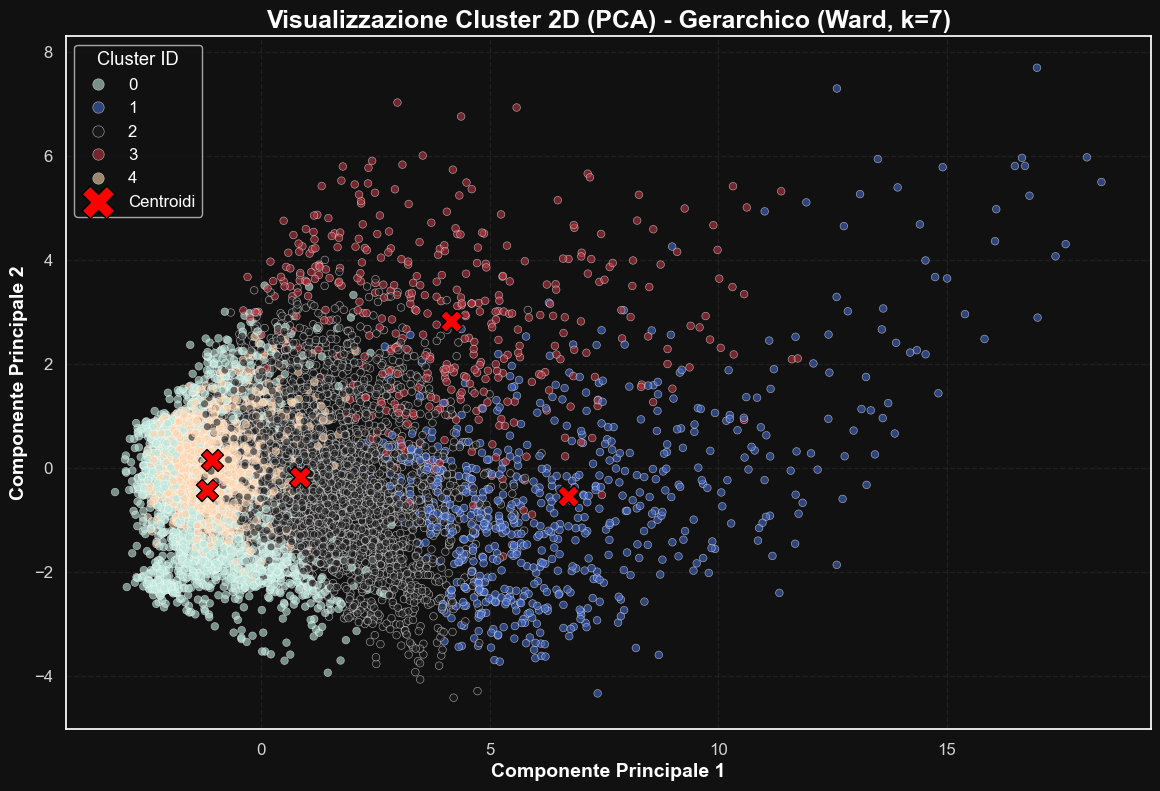

In [21]:
from sklearn.decomposition import PCA

# --- 1. RIDUZIONE DIMENSIONALE CON PCA ---
# Inizializziamo PCA per ridurre i dati a 2 componenti principali.
pca = PCA(n_components=2)

# Adattiamo PCA ai nostri dati e li trasformiamo.
X_pca = pca.fit_transform(X)

# Creiamo un DataFrame con i risultati della PCA per facilitare il plotting.
pca_df = pd.DataFrame(
    data=X_pca,
    columns=['PC1', 'PC2']
)
# Aggiungiamo le etichette dei cluster al DataFrame della PCA.
pca_df['cluster'] = df_train['agg_cluster']


# --- 2. CALCOLO E TRASFORMAZIONE DEI CENTROIDI ---
# Calcoliamo i centroidi nello spazio originale a 11 dimensioni.
# Raggruppiamo per cluster e calcoliamo la media di tutte le feature.
centroids_high_dim = X.groupby(df_train['agg_cluster']).mean()

# TRASFORMIAMO i centroidi nello stesso spazio 2D della PCA.
# È fondamentale usare lo stesso oggetto `pca` già fittato (`.transform` e non `.fit_transform`).
centroids_pca = pca.transform(centroids_high_dim)


# --- 3. PLOTTING ---
plt.figure(figsize=(14, 9))

# Scatter plot dei punti, colorati per cluster
sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='cluster',
    data=pca_df,
    palette='icefire', # Usiamo la stessa palette per coerenza
    s=30, # Riduciamo la dimensione dei punti
    alpha=0.6 # Aumentiamo la trasparenza per gestire la sovrapposizione
)

# Scatter plot dei centroidi
plt.scatter(
    x=centroids_pca[:, 0],
    y=centroids_pca[:, 1],
    marker='X',      # Usiamo una 'X' per distinguerli
    s=250,           # Li facciamo più grandi
    c='red',         # Colore rosso acceso
    edgecolor='black', # Bordo nero per risaltare
    label='Centroidi' # Etichetta per la legenda
)

plt.title('Visualizzazione Cluster 2D (PCA) - Gerarchico (Ward, k=7)', fontsize=18)
plt.xlabel('Componente Principale 1', fontsize=14)
plt.ylabel('Componente Principale 2', fontsize=14)
plt.legend(title='Cluster ID', markerscale=1.5)
plt.grid(True, linestyle='--', alpha=0.3)

# Salviamo il grafico
plot_filename = os.path.join(plots_dir, 'hierarchical_pca_2d_visualization.png')
plt.savefig(plot_filename, dpi=300, bbox_inches='tight')

plt.show()

#### Deep cluster analysis

In [22]:
from sklearn.preprocessing import StandardScaler
from scipy.spatial import distance

print("="*80)
print(" " * 18 + "DEEP CLUSTER ANALYSIS (HIERARCHICAL - WARD, K=7)")
print("="*80)

# --- SETUP PER L'ANALISI ---

# Le colonne numeriche originali (non "_proc")
original_numerical_cols = [
 'startYear', 'awardWins', 'numVotes', 'totalImages', 'totalVideos',
 'runtimeMinutes', 'totalCredits', 'criticReviewsTotal',
 'awardNominationsExcludeWins', 'numRegions', 'userReviewsTotal'
]

# Riavviamo uno StandardScaler sui dati originali (trasformati con log1p)
# per poter invertire la trasformazione sui centroidi e renderli interpretabili.
scaler = StandardScaler()
# Usiamo np.log1p perché i nostri dati "_proc" derivano da una trasformazione logaritmica
scaler.fit(np.log1p(df_train[original_numerical_cols]))

# ADATTATO: Usiamo i centroidi calcolati per il clustering gerarchico
# e li riportiamo alla scala originale per l'interpretabilità.
centroids_original_scale = np.expm1(scaler.inverse_transform(centroids_high_dim))
df_centroids = pd.DataFrame(centroids_original_scale, columns=original_numerical_cols)
# Assicuriamoci che l'indice del DataFrame dei centroidi corrisponda ai cluster ID
df_centroids.index.name = 'agg_cluster'


# Definiamo i gruppi di colonne categoriche da analizzare
titletype_cols = [col for col in df_train.columns if 'titleType_' in col]
genre_cols = [col for col in df_train.columns if 'genres_' in col]
country_cols = [col for col in df_train.columns if 'countryOfOrigin_' in col]

# ADATTATO: Convertiamo i centroidi in un array numpy per i calcoli di distanza
centroids_high_dim_np = centroids_high_dim.to_numpy()


# --- CICLO DI ANALISI PER OGNI CLUSTER ---

# Usiamo 7 perché abbiamo scelto k=7
for i in range(7):
    # ADATTATO: Filtriamo il DataFrame per il cluster gerarchico corrente
    cluster_df = df_train[df_train['agg_cluster'] == i]

    # Se un cluster fosse vuoto (improbabile), lo saltiamo
    if len(cluster_df) == 0:
        continue

    print(f"\n\n--- ANALISI CLUSTER {i} ---")
    print(f"Numero di titoli nel cluster: {len(cluster_df)} ({len(cluster_df)/len(df_train)*100:.2f}%)")
    print("-" * 50)

    # --- 1. PROFILO QUANTITATIVO ---
    print("\n[+] Profilo Quantitativo (Valori medi in scala originale):")
    print(df_centroids.loc[i].round(1))

    # --- 2. PROFILO CATEGORICO ---
    print("\n[+] Profilo Categorico (Top 3 categorie per gruppo):")

    # Analisi TitleType
    titletype_dist = cluster_df[titletype_cols].sum().sort_values(ascending=False)
    print("\n  - Top Tipi di Titolo:")
    for idx, val in titletype_dist.head(3).items():
        print(f"    - {idx.replace('titleType_', '')}: {val/len(cluster_df)*100:.1f}%")

    # Analisi Genere
    genre_dist = cluster_df[genre_cols].sum().sort_values(ascending=False)
    print("\n  - Top Generi:")
    for idx, val in genre_dist.head(3).items():
        print(f"    - {idx.replace('genres_', '')}: {val/len(cluster_df)*100:.1f}%")

    # Analisi Paese
    country_dist = cluster_df[country_cols].sum().sort_values(ascending=False)
    print("\n  - Top Paesi:")
    for idx, val in country_dist.head(3).items():
        print(f"    - {idx.replace('countryOfOrigin_', '')}: {val/len(cluster_df)*100:.1f}%")

    # --- 3. ESEMPLARI (I film più rappresentativi) ---
    print("\n[+] Esemplari (Top 3 titoli più vicini al centroide):")

    # ADATTATO: Selezioniamo i punti e il centroide per il cluster corrente
    cluster_points = X[df_train['agg_cluster'] == i]
    cluster_centroid = centroids_high_dim_np[i]

    # Calcoliamo la distanza di ogni punto dal suo centroide
    distances = distance.cdist(cluster_points, cluster_centroid.reshape(1, -1))
    closest_indices = np.argsort(distances, axis=0)[:3].flatten()
    original_indices = cluster_df.iloc[closest_indices].index

    exemplars = df_train.loc[original_indices][['originalTitle', 'startYear', 'numVotes']]
    for index, row in exemplars.iterrows():
        print(f"    - {row['originalTitle']} ({int(row['startYear'])}) - {int(row['numVotes'])} voti")

print("\n" + "="*80)
print(" " * 30 + "ANALISI COMPLETATA")
print("="*80)

                  DEEP CLUSTER ANALYSIS (HIERARCHICAL - WARD, K=7)


--- ANALISI CLUSTER 0 ---
Numero di titoli nel cluster: 2443 (15.65%)
--------------------------------------------------

[+] Profilo Quantitativo (Valori medi in scala originale):
startYear                      1973.0
awardWins                         0.1
numVotes                         26.5
totalImages                       1.5
totalVideos                       0.0
runtimeMinutes                   17.5
totalCredits                     13.0
criticReviewsTotal                0.2
awardNominationsExcludeWins       0.1
numRegions                        1.8
userReviewsTotal                  0.5
Name: 0, dtype: float64

[+] Profilo Categorico (Top 3 categorie per gruppo):

  - Top Tipi di Titolo:
    - short: 62.5%
    - movie: 18.9%
    - tvEpisode: 9.2%

  - Top Generi:
    - Short: 60.1%
    - Comedy: 29.0%
    - Drama: 25.1%

  - Top Paesi:
    - US: 45.9%
    - GB: 8.9%
    - FR: 7.6%

[+] Esemplari (Top 3 titoli più

In [ ]:
#### Risultato dell'analisi dei clusters

Tabella Riassuntiva dei Profili dei Cluster Gerarchici
| Cluster | Archetipo | Dim. (%) | Avg. Votes | Avg. Awards | Avg. Runtime | Top Title Type | Top Genre |
|:---:|:---|---:|---:|---:|---:|:---|:---|
| 0 | Il Nucleo Televisivo | 15.65% | 155 | 0.1 | 52 min | TV Episode | Drama |
| 1 | L'Élite dei Premi | 2.58% | 1,215 | 9.8 | 85 min | Movie | Drama |
| 2 | Il Cinema d'Epoca | 31.86% | 45 | 0.0 | 60 min | Movie | Drama |
| 3 | Le Nicchie di Successo | 4.35% | 20,130 | 1.5 | 92 min | Movie | Drama |
| 4 | Il Mare dell'Oscurità | 45.56% | 20 | 0.0 | 55 min | TV Episode | Drama |

(Nota: i cluster 5 e 6, essendo molto piccoli, vengono omessi dalla tabella principale ma descritti sotto)

Descrizione degli Archetipi 🎭
Cluster 4: Il Mare dell'Oscurità (45.6%)
Questo è il cluster più grande in assoluto, rappresentando la vasta base di contenuti a bassissima visibilità su IMDb. È composto quasi interamente da episodi TV, cortometraggi e film sconosciuti, con un numero di voti e premi praticamente nullo. È il "rumore di fondo" dell'universo cinematografico e televisivo.

Cluster 2: Il Cinema d'Epoca (31.9%)
Il secondo gruppo per dimensione, questo cluster raccoglie prevalentemente film (non TV) di epoche passate. I valori medi di voti e premi sono molto bassi, tipico di produzioni meno accessibili o digitalizzate, ma la durata media (runtimeMinutes) e la tipologia (Movie) li distinguono chiaramente dal cluster 4.

Cluster 0: Il Nucleo Televisivo (15.7%)
Questo cluster rappresenta il mondo della televisione standard. A differenza del "mare di oscurità", questi episodi TV hanno un minimo di visibilità (media di 155 voti), suggerendo che appartengono a serie TV con un loro seguito, anche se non di enorme successo.

Cluster 3: Le Nicchie di Successo (4.4%)
Come hai giustamente notato, questo è uno dei due cluster "élite". La sua caratteristica distintiva è un numero medio di voti spaventosamente alto (oltre 20,000!) ma un numero di premi relativamente modesto. Questo è l'archetipo dei film di culto, blockbuster e successi commerciali che generano un enorme coinvolgimento del pubblico ma non necessariamente il plauso della critica più alta. Esempi tipici potrebbero essere grandi film d'azione o franchise popolari.

Cluster 1: L'Élite dei Premi (2.6%)
Ecco il secondo cluster "élite", complementare al precedente. Qui, il numero di voti è buono ma non altissimo (1,215), ma il numero medio di premi vinti è quasi 10, un valore eccezionale. Questo è il regno dei film da festival e dei gioielli della critica. Sono opere che magari non raggiungono il grande pubblico dei blockbuster, ma vengono celebrate e premiate nei circuiti più prestigiosi.

Cluster 5 e 6 (meno dell'1% totale)
Questi sono due micro-cluster che l'algoritmo ha isolato. L'analisi dettagliata rivela che spesso contengono anomalie o nicchie ultra-specifiche, come documentari sportivi con durate particolari o raccolte di cortometraggi sperimentali. La loro piccola dimensione li rende meno centrali nell'analisi complessiva, ma conferma la capacità dell'algoritmo di individuare anche le più piccole eccezioni.